In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import pandas as pd

df = pd.read_csv(
    "/content/Reviews.csv",
    engine="python",
    on_bad_lines="warn"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

print("\nColumns:")
print(df.columns.tolist())
df.info()

Dataset loaded successfully!
Dataset shape: (27783, 10)


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...



Columns:
['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27783 entries, 0 to 27782
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Id                      27783 non-null  int64 
 1   ProductId               27783 non-null  object
 2   UserId                  27783 non-null  object
 3   ProfileName             27781 non-null  object
 4   HelpfulnessNumerator    27783 non-null  int64 
 5   HelpfulnessDenominator  27783 non-null  int64 
 6   Score                   27783 non-null  int64 
 7   Time                    27783 non-null  int64 
 8   Summary                 27783 non-null  object
 9   Text                    27783 non-null  object
dtypes: int64(5), object(5)
memory usage: 2.1+ MB


Score
1     2538
2     1613
3     2340
4     4070
5    17222
Name: count, dtype: int64


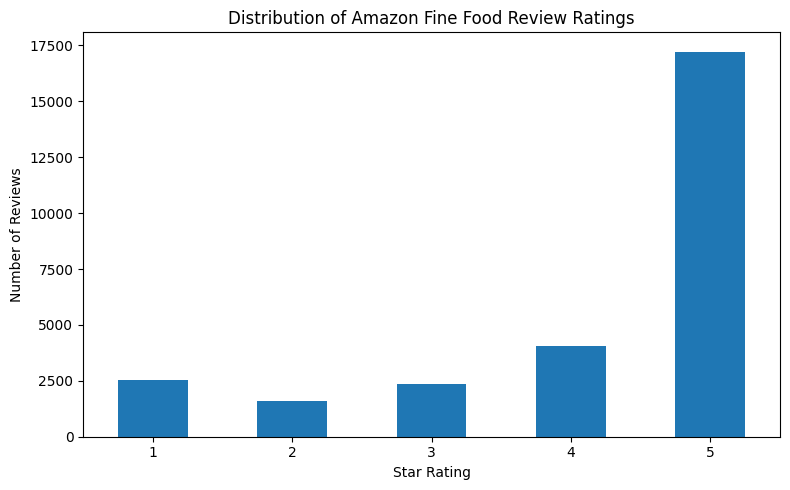

In [4]:
print(df["Score"].value_counts().sort_index())
df["Score"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(8,5)
)
plt.title("Distribution of Amazon Fine Food Review Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [5]:
def get_sentiment(score):
    if score <= 2:
        return "Negative"
    elif score == 3:
        return "Neutral"
    else:
        return "Positive"

df["Sentiment"] = df["Score"].apply(get_sentiment)
print(df["Sentiment"].value_counts())

Sentiment
Positive    21292
Negative     4151
Neutral      2340
Name: count, dtype: int64


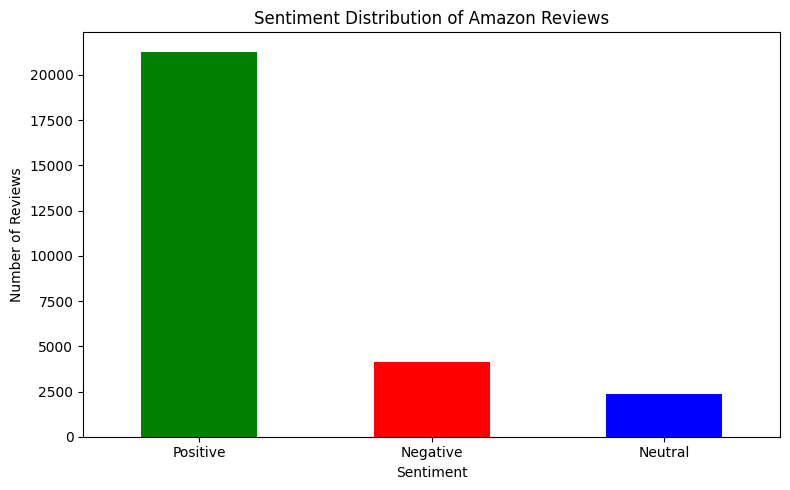

In [6]:
sentiment_counts=df["Sentiment"].value_counts()
sentiment_counts.plot(
    kind="bar",
    color=["green", "red", "blue"],
    figsize=(8,5)
)
plt.title("Sentiment Distribution of Amazon Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:

import re
import nltk
import pandas as pd
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

print("Libraries and text-processing resources are ready!")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Libraries and text-processing resources are ready!


In [8]:

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    words = text.split()
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]
    return " ".join(words)

print(clean_text(df["Text"].iloc[0]))


bought several vitality canned dog food product found good quality product look like stew processed meat smell better labrador finicky appreciates product better


In [9]:

df["Cleaned_Text"] = df["Text"].apply(clean_text)

print(df[["Text", "Cleaned_Text", "Sentiment"]].head())


                                                Text  \
0  I have bought several of the Vitality canned d...   
1  Product arrived labeled as Jumbo Salted Peanut...   
2  This is a confection that has been around a fe...   
3  If you are looking for the secret ingredient i...   
4  Great taffy at a great price.  There was a wid...   

                                        Cleaned_Text Sentiment  
0  bought several vitality canned dog food produc...  Positive  
1  product arrived labeled jumbo salted peanut pe...  Negative  
2  confection around century light pillowy citrus...  Positive  
3  looking secret ingredient robitussin believe f...  Negative  
4  great taffy great price wide assortment yummy ...  Positive  


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X = df["Cleaned_Text"]
y = df["Sentiment"]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

tfidf = TfidfVectorizer(max_features=10000)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Training reviews:", X_train.shape[0])
print("Testing reviews:", X_test.shape[0])
print("TF-IDF features:", X_train.shape[1])

Training reviews: 22226
Testing reviews: 5557
TF-IDF features: 10000


In [14]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

nb_pred = nb_model.predict(X_test)

nb_accuracy = accuracy_score(y_test, nb_pred)

print("Naive Bayes Accuracy:", round(nb_accuracy * 100, 2), "%")

Naive Bayes Accuracy: 77.97 %


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

lr_accuracy = accuracy_score(y_test, lr_pred)

print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 84.18 %


In [ ]:

print("Model Accuracy Comparison")
print("Naive Bayes:", round(nb_accuracy * 100, 2), "%")
print("Logistic Regression:", round(lr_accuracy * 100, 2), "%")


Model Accuracy Comparison
Naive Bayes: 77.29 %
Logistic Regression: 83.03 %



Naive Bayes
Accuracy:  0.8303
Precision: 0.8009
Recall:    0.8303
F1-score:  0.7992

Classification Report:
              precision    recall  f1-score   support

    Negative       0.71      0.53      0.61       847
     Neutral       0.50      0.10      0.17       486
    Positive       0.85      0.97      0.91      4224

    accuracy                           0.83      5557
   macro avg       0.69      0.54      0.56      5557
weighted avg       0.80      0.83      0.80      5557



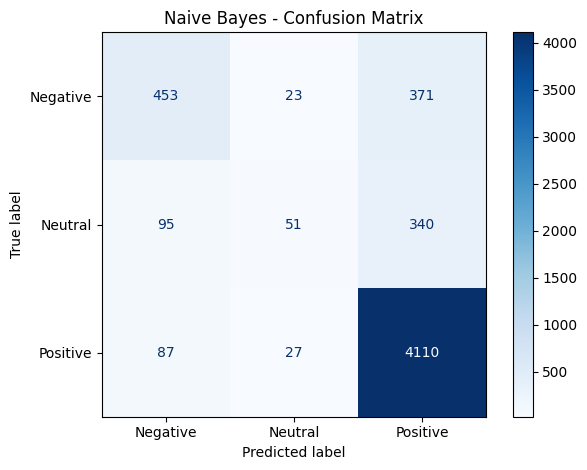


Logistic Regression
Accuracy:  0.8303
Precision: 0.8009
Recall:    0.8303
F1-score:  0.7992

Classification Report:
              precision    recall  f1-score   support

    Negative       0.71      0.53      0.61       847
     Neutral       0.50      0.10      0.17       486
    Positive       0.85      0.97      0.91      4224

    accuracy                           0.83      5557
   macro avg       0.69      0.54      0.56      5557
weighted avg       0.80      0.83      0.80      5557



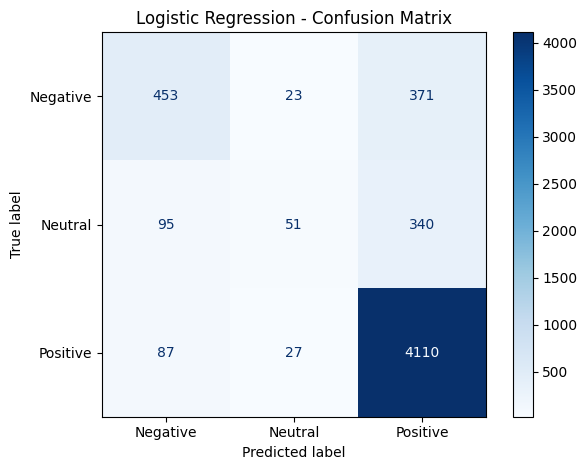

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
models = {
    "Naive Bayes": (y_test, y_pred),
    "Logistic Regression": (y_test, y_pred)
}
for name, (actual, predicted) in models.items():
    print(f"\n{'=' * 45}")
    print(name)
    print(f"{'=' * 45}")

    print(f"Accuracy:  {accuracy_score(actual, predicted):.4f}")
    print(f"Precision: {precision_score(actual, predicted, average='weighted', zero_division=0):.4f}")
    print(f"Recall:    {recall_score(actual, predicted, average='weighted', zero_division=0):.4f}")
    print(f"F1-score:  {f1_score(actual, predicted, average='weighted', zero_division=0):.4f}")

    print("\nClassification Report:")
    print(classification_report(
        actual,
        predicted,
        labels=["Negative", "Neutral", "Positive"],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        actual,
        predicted,
        labels=["Negative", "Neutral", "Positive"],
        cmap="Blues",
        values_format="d"
    )
    plt.title(f"{name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()


In [ ]:
%pip install wordcloud

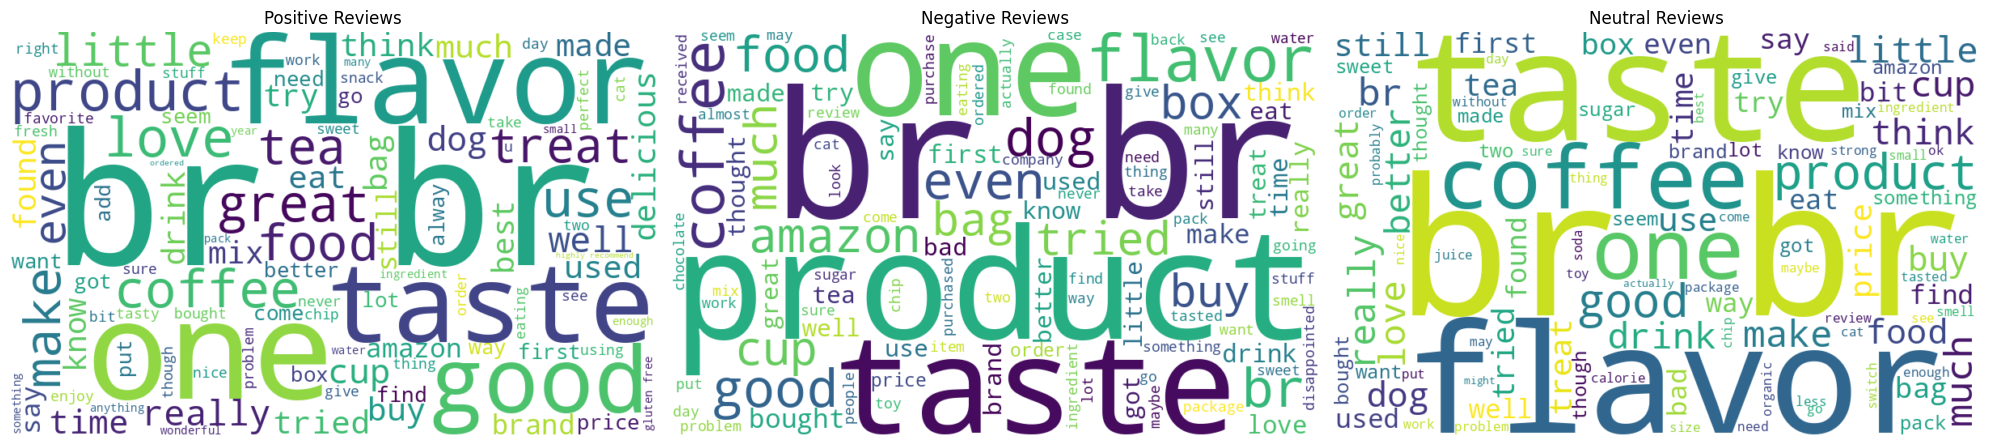

In [ ]:

from wordcloud import WordCloud
import matplotlib.pyplot as plt

sentiments = ["Positive", "Negative", "Neutral"]

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

for ax, sentiment in zip(axes, sentiments):
    text = " ".join(
        df.loc[df["Sentiment"] == sentiment, "Cleaned_Text"]
        .dropna()
        .astype(str)
    )
    wordcloud = WordCloud(
        width=800,
        height=500,
        background_color="white",
        max_words=100
    ).generate(text)

    ax.imshow(wordcloud, interpolation="bilinear")
    ax.set_title(f"{sentiment} Reviews")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [16]:
error_analysis = pd.DataFrame({
    "Actual Sentiment": y_test,
    "Predicted Sentiment": lr_pred,
    "Review": df.loc[X_test_text.index, "Text"]
})

misclassified = error_analysis[
    error_analysis["Actual Sentiment"] != error_analysis["Predicted Sentiment"]
]

print("Total Misclassified Reviews:", len(misclassified))

display(misclassified.head(5))

Total Misclassified Reviews: 879


,Actual Sentiment,Predicted Sentiment,Review
4430,Neutral,Positive,While I love Bit a Honey and don't regret my p...
20684,Negative,Positive,I purchased this product as an alternative to ...
3302,Neutral,Positive,I bought this brand of hot chocolate K cups ca...
12735,Neutral,Positive,I hate chocolate. I used to have this on subsc...
24984,Neutral,Negative,I actually thought I was buying the Van Houtte...


### Error Analysis

The Logistic Regression model misclassified 879 reviews from the test dataset. Five misclassified examples were examined to understand the reasons behind incorrect predictions.

Some possible reasons for misclassification include:

- Ambiguous language and mixed opinions.
- Sarcasm and context-dependent expressions.
- Product-related words influencing sentiment predictions.
- Differences between star ratings and the actual emotional tone of reviews.
- Neutral reviews containing strongly positive or negative words.

This analysis shows that sentiment classification can be challenging because individual words do not always represent the overall meaning of a review.


In [18]:
from sklearn.metrics import f1_score

print("Naive Bayes F1-score:", round(f1_score(y_test, nb_pred, average="weighted"), 4))

print("Logistic Regression F1-score:", round(f1_score(y_test, lr_pred, average="weighted"), 4))

Naive Bayes F1-score: 0.6956
Logistic Regression F1-score: 0.8132


### Conclusion

In this project, I worked on analysing Amazon Fine Food Reviews and classifying them into Positive, Negative, and Neutral sentiments using machine learning.

I started by cleaning the review text using lowercasing, punctuation removal, stopword removal, and lemmatization. Then, I used TF-IDF to convert the text into numerical features and trained two models: Naive Bayes and Logistic Regression.

After evaluating both models, Logistic Regression gave better results with an accuracy of 84.18% and a weighted F1-score of 0.8132, compared to Naive Bayes, which achieved an accuracy of 77.97% and a weighted F1-score of 0.6956.

From this comparison, I found that Logistic Regression performed better on this dataset.

This project helped me understand how machine learning can be used to analyse customer reviews and identify their opinions about products. Such a system can be useful for businesses to understand customer feedback and improve their products and services.

One limitation I noticed is that some reviews may not express the same sentiment as their star ratings, which can lead to incorrect predictions.